In [ ]:
# 큰 데이터일 때 예측에 사용하는 모형으로 예측, 분류
# 자료는 fish_logistic.csv 파일을 사용해서 logisticRegression모델로 실행

In [4]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge, Lasso, LogisticRegression, SGDClassifier # 이 파트는 반드시 알아둘 것
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  # 다항특성 자동생성, # 정규화클래스
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit는 이진분류함수, softmax는 다중분류함수 => 0~1사이의 숫자로 변환시키는 기능

In [8]:
df = pd.read_csv('../data/fish_logistic.csv')
df.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [10]:
data = df[df.columns[1:]].values
data[:2]

array([[242.    ,  25.4   ,  30.    ,  11.52  ,   4.02  ],
       [290.    ,  26.3   ,  31.2   ,  12.48  ,   4.3056]])

In [11]:
label = df['Species'].values
label[:2]

<StringArray>
['Bream', 'Bream']
Length: 2, dtype: str

In [12]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [14]:
ss = StandardScaler()
ss.fit(train_data,train_label)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [15]:
sc = SGDClassifier(loss="log_loss",random_state=42)
train_score = []
test_score = []
classes = np.unique(train_label)
for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

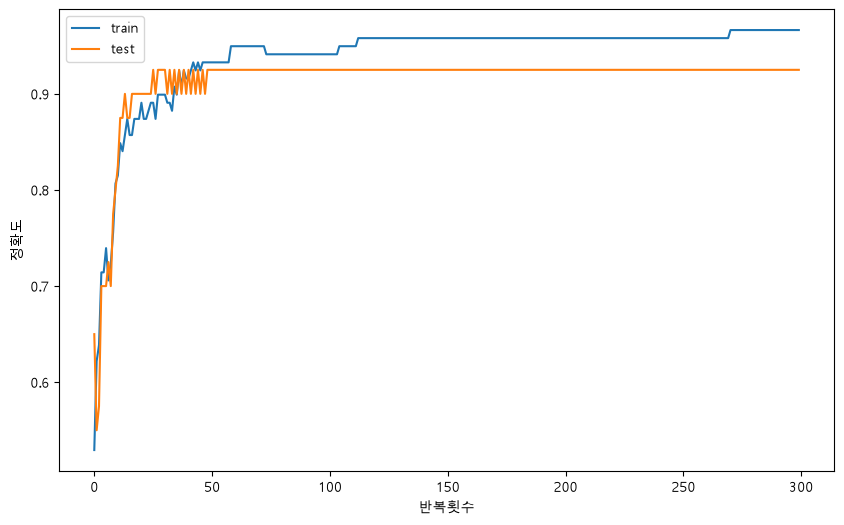

In [17]:
plt.figure(figsize=(10,6))
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.legend(['train','test'])
plt.show()

In [18]:
# 첫번째 학습 모델 생성
sc = SGDClassifier(loss="log_loss", max_iter=100, tol=None)
sc.fit(train_scaled,train_label)
print("train정확도", sc.score(train_scaled,train_label))
print("test정확도", sc.score(test_scaled,test_label))

train정확도 0.957983193277311
test정확도 0.925


In [19]:
# 추가 데이터를 반영하여 추가 모델 학습결과
sc.partial_fit(train_scaled,train_label)
print("train정확도", sc.score(train_scaled,train_label))
print("test정확도", sc.score(test_scaled,test_label))

train정확도 0.8907563025210085
test정확도 0.95
